# Main results: Table 1, Figures 2–5, Table A3, Figure A2

Reproduces the cohort-forecast results in *Can a Simple Neural Network Improve Cohort Fertility Forecasts?* Each section is headed with the paper item it produces. Run top to bottom; later sections reuse objects built in the two setup sections.

Figures are written to `../../figures/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Arial throughout, to match the other figures in the paper
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "pdf.fonttype": 42,   # embed TrueType fonts (journal-friendly)
    "ps.fonttype": 42,
})

## Setup: load forecasts

In [ ]:
# ============================================================
# Model registry: single source of truth for every forecast series.
# Add or remove a model HERE and it flows through all tables & plots below.
# ============================================================
# Each entry: label -> dict(pred, obs, color, marker, in_common)
#   pred/obs    : CSV basenames in ../../data
#   color/marker: styling for the trajectory & per-country plots
#   in_common   : whether the model joins the shared-grid intersection used by the
#                 headline RMSE tables. 
MODEL_REGISTRY = {
    'Lee':        dict(pred='lee2_forecasts_cohort',                obs='lee2_obs_cohort',                       color='#d62728', marker='o', in_common=True),
    'CCF-Net':        dict(pred='dl_forecasts_CCF_Net_u110_l4_d0.0_w40',           obs='dl_obs_cohort_CCF_Net_u110_l4_d0.0_w40',         color='#8c564b', marker='*', in_common=True),
    'Freeze rates':      dict(pred='freeze_forecasts_cohort',              obs='freeze_obs_cohort',                     color='#2ca02c', marker='^', in_common=True),
    'Myrskyla et al.':     dict(pred='myrskyla_forecasts_cohort',            obs='myrskyla_obs_cohort',                   color='#9467bd', marker='P', in_common=True),
    'de Beer':           dict(pred='debeer2_forecasts_cohort',             obs='debeer2_obs_cohort',                    color='#ff7f0e', marker='X', in_common=True),
    'Schmertmann et al.':  dict(pred='schmertmann2013_forecasts_cohort',     obs='schmertmann2013_obs_cohort',            color='#7f7f7f', marker='D', in_common=True),
    'Sevcikova et al.':    dict(pred='sevcikova_forecasts_cohort',           obs='sevcikova_obs_cohort',                  color='#e377c2', marker='h', in_common=True),
}

DATA_DIR = '../../data'
key_cols = ['Country', 'Year', 'Age', 'JumpOffYear']

# Observed frames have one row per (Country, Year, Age): an observed rate does not
# depend on the jump-off year, so it is matched to forecasts on obs_key, not
# key_cols. drop_duplicates also lets this read older obs files that repeated
# every cell once per jump-off year.
obs_key = ['Country', 'Year', 'Age']


def load_obs(path):
    return (pd.read_csv(path).drop_duplicates(obs_key)
            .drop(columns='JumpOffYear', errors='ignore'))

# Age window models are scored on
SCORE_AGE_LO, SCORE_AGE_HI = 15, 40

# geo index -> HFD country code, for every plot that labels a country axis.
GEO_NAMES = {int(idx): str(name)
             for name, idx in np.load(f'{DATA_DIR}/geos_key.npy', allow_pickle=True)}

# HFD country code -> full name, used only for figure labels (the codes above
# stay the keys for all filtering logic, e.g. PANEL_EXCLUDE, POST_SOCIALIST).
COUNTRY_NAMES = {
    'AUT': 'Austria', 'BEL': 'Belgium', 'BGR': 'Bulgaria', 'BLR': 'Belarus',
    'CAN': 'Canada', 'CHE': 'Switzerland', 'CHL': 'Chile', 'CZE': 'Czechia',
    'DEUTE': 'East Germany', 'DEUTNP': 'Germany', 'DEUTW': 'West Germany',
    'DNK': 'Denmark', 'ESP': 'Spain', 'EST': 'Estonia', 'FIN': 'Finland',
    'FRATNP': 'France', 'GBR_NIR': 'Northern Ireland', 'GBR_NP': 'United Kingdom',
    'GBR_SCO': 'Scotland', 'GBRTENW': 'England & Wales', 'HRV': 'Croatia',
    'HUN': 'Hungary', 'IRL': 'Ireland', 'ISL': 'Iceland', 'ITA': 'Italy',
    'JPN': 'Japan', 'KOR': 'South Korea', 'LTU': 'Lithuania', 'NLD': 'Netherlands',
    'NOR': 'Norway', 'POL': 'Poland', 'PRT': 'Portugal', 'RUS': 'Russia',
    'SVK': 'Slovakia', 'SVN': 'Slovenia', 'SWE': 'Sweden', 'TWN': 'Taiwan',
    'UKR': 'Ukraine', 'USA': 'United States',
}

def geo_label(c):
    """Full country name for a geo index (or code), falling back to the code."""
    code = GEO_NAMES.get(int(c), str(c)) if not isinstance(c, str) else c
    return COUNTRY_NAMES.get(code, code)

# label -> mutable dict with loaded frames + styling
M = {}
for label, meta in MODEL_REGISTRY.items():
    M[label] = {
        'pred':  pd.read_csv(f"{DATA_DIR}/{meta['pred']}.csv"),
        'obs':   load_obs(f"{DATA_DIR}/{meta['obs']}.csv"),
        'color': meta['color'], 'marker': meta['marker'], 'in_common': meta['in_common'],
    }

# models that share the common forecast grid (everything except Schmertmann)
common_labels = [l for l, m in M.items() if m['in_common']]
print("Loaded models:  ", list(M))
print("Common grid:    ", common_labels)

Loaded models:   ['Lee', 'CCF-Net', 'Freeze rates', 'Myrskyla et al.', 'de Beer', 'Schmertmann et al.', 'Sevcikova et al.']
Common grid:     ['Lee', 'CCF-Net', 'Freeze rates', 'Myrskyla et al.', 'de Beer', 'Schmertmann et al.', 'Sevcikova et al.']


In [3]:
# Filter forecasts to only periods after the jump-off year (drop reproduced observed
# rates), then restrict BOTH the forecast and the observed frames to the scored age
# window. Doing it here means every table and figure downstream -- pointwise RMSE,
# RMSE by jump-off year / country / horizon, the CF tables, the ensemble table --
# sees the same cells.
# Year is the birth cohort; the period of each observation is Year + Age.
for label, m in M.items():
    p = m['pred']
    m['pred'] = p[(p['Year'] + p['Age'] > p['JumpOffYear']) &
                  p['Age'].between(SCORE_AGE_LO, SCORE_AGE_HI)]
    o = m['obs']
    m['obs'] = o[o['Age'].between(SCORE_AGE_LO, SCORE_AGE_HI)]

print(f'Scored age window: {SCORE_AGE_LO}-{SCORE_AGE_HI}')
for label, m in M.items():
    print(f"  {label:<20} pred {len(m['pred']):>7,} cells   "
          f"obs {len(m['obs']):>7,} cells")

Scored age window: 15-40
  Lee                  pred 553,020 cells   obs  62,348 cells
  CCF-Net              pred 807,300 cells   obs  66,456 cells
  Freeze rates         pred 804,960 cells   obs  66,456 cells
  Myrskyla et al.      pred 796,380 cells   obs  66,456 cells
  de Beer              pred 777,920 cells   obs  62,348 cells
  Schmertmann et al.   pred 260,650 cells   obs  48,946 cells
  Sevcikova et al.     pred 283,075 cells   obs  64,558 cells


In [4]:
# Keep only the forecast cells that every common-grid model (in_common=True) has,
# matched on identifiers, not Rate. Currently every model is on the common grid.
common_keys = M[common_labels[0]]['pred'][key_cols].drop_duplicates()
for label in common_labels[1:]:
    common_keys = common_keys.merge(
        M[label]['pred'][key_cols].drop_duplicates(), on=key_cols, how='inner')

for label in common_labels:
    M[label]['pred'] = M[label]['pred'].merge(common_keys, on=key_cols, how='inner')

print(f"Common grid: {len(common_keys):,} cells across {len(common_labels)} models "
      f"({', '.join(common_labels)})")

Common grid: 228,800 cells across 7 models (Lee, CCF-Net, Freeze rates, Myrskyla et al., de Beer, Schmertmann et al., Sevcikova et al.)


## Setup: completed cohort fertility (used by every section below)

In [ ]:
# ============================================================
# Completed cohort fertility (CF): absolute percentage errors
# ============================================================
# This is the error set behind Table 1 of Bohk-Ewald, Li & Myrskyla (2018),
# "Forecast accuracy hardly improves with method complexity when completing
# cohort fertility" (PNAS 115:9187-9192). Everything below scores COMPLETED
# COHORT FERTILITY, not pointwise ASFR.
#
# Their construction (SI Appendix, SI2 "Procedural steps" and Fig. S1):
#   CF        = sum of ASFR over ages 15..40 of one birth cohort ("CF40").
#   AAF       = age at forecast = the cohort's age in the jump-off year (JOY).
#               A cohort aged AAF in the JOY has ages 15..AAF observed; the
#               method forecasts ages AAF+1..40. AAF 39 means one forecast
#               year, AAF 20 means twenty.
#   Forecast CF = observed history (ages 15..AAF) + forecast (ages AAF+1..40),
#               so CF errors come only from the forecast part but are expressed
#               relative to the whole cohort's fertility.
#   APE       = |CF_forecast - CF_observed| / CF_observed * 100, one error per
#               (country, birth cohort, JOY). The paper keeps AAF 20-39, giving
#               20 CF forecasts per country and JOY.
#
# AGE SPAN: the paper uses CF40 because the HFD vintage they used could not
# complete more cohorts at 44. Our data run to age 44, so CF44 is a defensible
# alternative -- it drops ~13% of the cohorts (they must be observed five years
# longer). Checked: the mean-APE ordering of the methods is the same under CF44
# (Myrskyla and Sevcikova, near-tied either way, trade places); the KS column was
# not re-verified. CF40 is kept as the default so the numbers read against the
# published table. The span is NOT set here: it is SCORE_AGE_LO/HI from the load
# cell, the same window the pointwise tables use, so the two views cannot drift
# apart. To try CF44, change SCORE_AGE_HI up top and rerun the whole notebook.
from scipy.stats import ks_2samp

CF_AGE_LO, CF_AGE_HI = SCORE_AGE_LO, SCORE_AGE_HI   # CF40, as in the paper
N_CF_AGES = CF_AGE_HI - CF_AGE_LO + 1   # ages needed for a "complete" cohort
AAF_LO, AAF_HI = 20, 39                 # truncation ages retained (paper: 20-39)
DOMINANCE_ALPHA = 0.05

# name -> (observed df, forecast df), built from the registry. Forecasts are
# already filtered to post-jump-off cells on the shared grid (cells above).
models = {label: (m['obs'], m['pred']) for label, m in M.items()}


def cf_ape(obs_df, pred_df):
    """APE (%) of completed cohort fertility, indexed by (Country, Year, JumpOffYear).

    `Year` is the birth cohort; a cell's calendar period is Year + Age, so the
    cohort's age in jump-off year `joy` (its AAF) is joy - Year.
    """
    obs = (obs_df[obs_df['Age'].between(CF_AGE_LO, CF_AGE_HI)]
           [['Country', 'Year', 'Age', 'Rate']]
           .drop_duplicates(['Country', 'Year', 'Age']))

    # true CF: cohorts observed across every age in the span (actually complete)
    n_obs_ages = obs.groupby(['Country', 'Year'])['Age'].transform('nunique')
    true_cf = obs[n_obs_ages == N_CF_AGES].groupby(['Country', 'Year'])['Rate'].sum()

    apes = {}
    for joy in sorted(pred_df['JumpOffYear'].unique()):
        obs_hist = obs[obs['Year'] + obs['Age'] <= joy]          # ages 15..AAF
        fcast = pred_df[pred_df['JumpOffYear'] == joy][['Country', 'Year', 'Age', 'Rate']]
        fcast = fcast[(fcast['Year'] + fcast['Age'] > joy) &
                      fcast['Age'].between(CF_AGE_LO, CF_AGE_HI)]   # ages AAF+1..40
        traj = pd.concat([obs_hist, fcast])                      # spliced trajectory
        n_traj_ages = traj.groupby(['Country', 'Year'])['Age'].transform('nunique')
        fcast_cf = traj[n_traj_ages == N_CF_AGES].groupby(['Country', 'Year'])['Rate'].sum()

        for (country, byear) in fcast_cf.index.intersection(true_cf.index):
            if AAF_LO <= joy - byear <= AAF_HI:                  # truncation-age window
                obs_v, fc_v = true_cf[(country, byear)], fcast_cf[(country, byear)]
                apes[(country, byear, joy)] = abs(fc_v - obs_v) / obs_v * 100
    return pd.Series(apes, name='APE')


ape_raw = {name: cf_ape(o, p) for name, (o, p) in models.items()}

# Equal testing dataset (paper, SI2 "Compare forecast errors"): the largest
# intersection of the CF forecasts of all methods, so every pairwise KS test
# and every summary statistic below describes the identical set of cohorts.
common_cohorts = None
for s in ape_raw.values():
    common_cohorts = s.index if common_cohorts is None else common_cohorts.intersection(s.index)
ape_by_model = {name: s.loc[common_cohorts] for name, s in ape_raw.items()}

_idx = pd.DataFrame(list(common_cohorts), columns=['Country', 'Cohort', 'JumpOffYear'])
print(f'Equal testing dataset: {len(common_cohorts):,} CF forecast errors '
      f'({_idx.Country.nunique()} countries x {_idx.Cohort.nunique()} birth cohorts '
      f'x {_idx.JumpOffYear.nunique()} jump-off years), CF ages '
      f'{CF_AGE_LO}-{CF_AGE_HI}, truncation ages {AAF_LO}-{AAF_HI}.')
print('Errors available per method BEFORE equalizing: '
      + ', '.join(f'{n} {len(s):,}' for n, s in ape_raw.items()))

ape_summary = pd.DataFrame({
    'N':          {n: len(s)     for n, s in ape_by_model.items()},
    'median_APE': {n: s.median() for n, s in ape_by_model.items()},
    'mean_APE':   {n: s.mean()   for n, s in ape_by_model.items()},
}).sort_values('median_APE')
ape_summary

Equal testing dataset: 11,599 CF forecast errors (32 countries x 39 birth cohorts x 29 jump-off years), CF ages 15-40, truncation ages 20-39.
Errors available per method BEFORE equalizing: Lee 11,599, CCF-Net 11,599, Freeze rates 11,599, Myrskyla et al. 11,599, de Beer 11,599, Schmertmann et al. 11,599, Sevcikova et al. 11,599


,N,median_APE,mean_APE
Myrskyla et al.,11599,1.072730,3.135703
CCF-Net,11599,1.150634,3.021485
Schmertmann et al.,11599,1.286597,3.090223
de Beer,11599,1.349235,3.440089
Sevcikova et al.,11599,1.660229,3.313891
Lee,11599,1.814746,4.192203
Freeze rates,11599,2.161210,3.989873


In [ ]:
# ============================================================
# Completed cohort fertility LEVELS per method (Figures 3, 4 and A2)
# ============================================================
# For each (country, cohort, jump-off year), a method's CF is the cohort's
# OBSERVED rates at ages 15..AAF plus that method's FORECAST rates at ages
# AAF+1..40. Built from the RAW registry files rather than the common-grid
# frames, because Figures 4 and A2 show every forecast a method publishes.
CMP_AAF_LO, CMP_AAF_HI = 15, 39               # 15 = one observed rate; 39 = one forecast year
CMP_SCORE_AAF_LO = 20                         # scorable floor, as in Table 1


def spliced_cf(pred_df, obs_df, aaf_lo=CMP_AAF_LO, aaf_hi=CMP_AAF_HI):
    """Completed cohort fertility per (Country, cohort, jump-off year).

    Same construction as `cf_ape` above (observed history + forecast tail, kept
    only where the spliced trajectory covers ages CF_AGE_LO..CF_AGE_HI), but
    returns the CF LEVEL rather than an APE, and keeps cohorts that are not yet
    complete in the data. `true_cf` is NaN for exactly those cohorts.
    """
    obs = (obs_df[obs_df['Age'].between(CF_AGE_LO, CF_AGE_HI)]
           [['Country', 'Year', 'Age', 'Rate']]
           .drop_duplicates(['Country', 'Year', 'Age']))
    n_obs_ages = obs.groupby(['Country', 'Year'])['Age'].transform('nunique')
    true_cf = obs[n_obs_ages == N_CF_AGES].groupby(['Country', 'Year'])['Rate'].sum()

    out = []
    for joy in sorted(pred_df['JumpOffYear'].unique()):
        obs_hist = obs[obs['Year'] + obs['Age'] <= joy]                  # ages 15..AAF
        fcast = pred_df[pred_df['JumpOffYear'] == joy][['Country', 'Year', 'Age', 'Rate']]
        fcast = fcast[(fcast['Year'] + fcast['Age'] > joy) &
                      fcast['Age'].between(CF_AGE_LO, CF_AGE_HI)]        # ages AAF+1..40
        traj = pd.concat([obs_hist, fcast])
        n_traj = traj.groupby(['Country', 'Year'])['Age'].transform('nunique')
        cf = (traj[n_traj == N_CF_AGES].groupby(['Country', 'Year'])['Rate']
              .sum().reset_index(name='cf'))
        cf['JumpOffYear'] = joy
        out.append(cf)

    res = pd.concat(out, ignore_index=True)
    res['AAF'] = res['JumpOffYear'] - res['Year']
    res = res[res['AAF'].between(aaf_lo, aaf_hi)].copy()
    res['true_cf'] = pd.MultiIndex.from_arrays(
        [res['Country'], res['Year']]).map(true_cf)
    return res


# CF levels for every method, from the raw registry files.
cf_level = {label: spliced_cf(pd.read_csv(f"{DATA_DIR}/{meta['pred']}.csv"),
                              pd.read_csv(f"{DATA_DIR}/{meta['obs']}.csv"))
            for label, meta in MODEL_REGISTRY.items()}

## Table 1: ranking of methods on CF forecast accuracy

In [ ]:
# ============================================================
# Table 1, KS column: stochastic dominance with country-level permutation p-values
# ============================================================
# KS(A, B) is the one-sided two-sample KS statistic sup(F_A - F_B) on the CF-APEs.
# A large value means A's error CDF lies to the LEFT of B's: A's errors are
# systematically smaller, so A stochastically dominates (forecasts better than) B.
#
# CROSSOVER: as in Bohk-Ewald et al., the test is run in both directions. If both
# KS(A,B) and KS(B,A) are significant the CDFs cross, neither method dominates,
# and the pair counts toward neither method's score.
#
# P-VALUES. scipy's KS formula assumes every APE is an independent draw. They are
# not: the same cohort is forecast at up to 20 jump-off years, neighbouring cohorts
# share the same period shocks, and some countries are simply harder to forecast
# (AAF-adjusted log-APE correlation ~0.76 between neighbouring cohorts at the same
# JOY). Clustering shrinks the effective sample size and makes the naive p-values
# too small. The two methods are also scored on the SAME cohorts (positively
# correlated errors), which the unpaired formula ignores and which pushes the
# other way.
#
# So the KS STATISTIC is the standard one, but its null distribution comes from a
# permutation test. If the two methods were equally accurate (H0), it would be
# arbitrary which of a country's two APEs belongs to which method. Each
# permutation therefore picks a random half (on average) of the countries -- each
# country independently, with probability 1/2 -- and swaps the two methods' APEs
# on every row of those countries, then recomputes the KS statistic. Swapping
# within a row keeps the pairing (both methods are still scored on the same
# cohort); swapping a whole country at once keeps the within-country dependence.
# Repeating this N_PERM times gives the distribution of the statistic under H0.
# The p-value is the share of permutations whose statistic is at least as large
# as the observed one: (1 + #{D_perm >= D_obs}) / (1 + N_PERM).
#
# Remaining assumption: countries are independent of one another (shared
# cross-country trends are not modelled), so these p-values may still be
# slightly optimistic.
names = list(ape_by_model)
N_PERM = 10_000
PERM_SEED = 0

# one cluster id per row of ape_by_model; `_idx` (CF cell) lists common_cohorts in order
_cluster = pd.factorize(_idx['Country'])[0]
_n_clusters = _cluster.max() + 1
assert len(_cluster) == len(common_cohorts) and _n_clusters == _idx['Country'].nunique()
_flips = np.random.default_rng(PERM_SEED).integers(
    0, 2, size=(N_PERM, _n_clusters)).astype(np.int8)
_PERM_BATCH = 500


def perm_ks(x, y):
    """Observed one-sided KS statistics and their country-permutation p-values.

    Returns (D(x,y), D(y,x), p(x,y), p(y,x)) where D(x,y) = max_t F_x(t) - F_y(t).
    The pooled sample is the same multiset under every swap, so it is sorted
    once; F_x - F_y along it is then a running sum of +1 (row's value sits in x)
    and -1 (in y), read at the last position of each tie group.
    """
    n = len(x)
    pooled = np.concatenate([x, y])
    order = np.argsort(pooled, kind='stable')
    vals = pooled[order]
    last_of_tie = np.r_[vals[1:] != vals[:-1], True]
    base = np.where(order < n, 1, -1).astype(np.int32)   # +1 from x, -1 from y
    clus = _cluster[order % n]                           # country of each sorted value

    obs = np.cumsum(base)[last_of_tie]
    d_xy, d_yx = obs.max() / n, -obs.min() / n
    hits_xy = hits_yx = 0
    for b0 in range(0, N_PERM, _PERM_BATCH):
        swap = _flips[b0:b0 + _PERM_BATCH][:, clus]       # 1 = this row is swapped
        gap = np.cumsum(base * (1 - 2 * swap.astype(np.int32)), axis=1)[:, last_of_tie]
        hits_xy += int((gap.max(axis=1) / n >= d_xy - 1e-12).sum())
        hits_yx += int((-gap.min(axis=1) / n >= d_yx - 1e-12).sum())
    return d_xy, d_yx, (1 + hits_xy) / (1 + N_PERM), (1 + hits_yx) / (1 + N_PERM)


perm_pval = pd.DataFrame(1.0, index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        d_ab, d_ba, p_ab, p_ba = perm_ks(ape_by_model[a].values, ape_by_model[b].values)
        # sanity check: same statistic as scipy's one-sided KS; only the null differs
        assert np.isclose(d_ab, ks_2samp(ape_by_model[a].values, ape_by_model[b].values,
                                         alternative='greater').statistic)
        assert np.isclose(d_ba, ks_2samp(ape_by_model[b].values, ape_by_model[a].values,
                                         alternative='greater').statistic)
        perm_pval.loc[a, b], perm_pval.loc[b, a] = p_ab, p_ba

significant_perm = perm_pval < DOMINANCE_ALPHA
crossover_perm = significant_perm & significant_perm.T
dominates_perm = significant_perm & ~crossover_perm
ks_score_perm = dominates_perm.sum(axis=1)

# Monte Carlo error of each p-value; flag decisions that could flip on a rerun
_mc_se = np.sqrt(perm_pval * (1 - perm_pval) / N_PERM)
_borderline = [(a, b, perm_pval.loc[a, b]) for a in names for b in names
               if a != b and abs(perm_pval.loc[a, b] - DOMINANCE_ALPHA) < 2 * _mc_se.loc[a, b]]

print(f'Country-level paired permutation KS: {N_PERM:,} permutations over '
      f'{_n_clusters} countries (seed {PERM_SEED}). p-value floor {1 / (1 + N_PERM):.1e}.')
print('\nPermutation p-values  (row beats column):')
display(perm_pval.round(4))
print(f'\nStochastic dominance at alpha={DOMINANCE_ALPHA}, permutation p-values:')
display(dominates_perm)
if _borderline:
    print('Within 2 Monte Carlo SE of alpha (decision could flip with another seed):')
    for a, b, p in _borderline:
        print(f'  {a} over {b}: p = {p:.4f}')

print('\nScoreboard (ks_score_perm is the KS column of Table 1)')
pd.DataFrame({
    'ks_score_perm':   ks_score_perm,
    'dominated_by_n':  dominates_perm.sum(axis=0),
    'crossovers_n':    crossover_perm.sum(axis=1),
}).sort_values(['ks_score_perm', 'dominated_by_n'], ascending=[False, True])

Country-level paired permutation KS: 10,000 permutations over 32 countries (seed 0). p-value floor 1.0e-04.

Permutation p-values  (row beats column):


,Lee,CCF-Net,Freeze rates,Myrskyla et al.,de Beer,Schmertmann et al.,Sevcikova et al.
Lee,1.0000,0.9634,0.0044,0.9543,0.9971,0.7102,0.0264
CCF-Net,0.0001,1.0000,0.0001,0.4999,0.0265,0.0192,0.0001
Freeze rates,0.0398,0.9922,1.0000,0.6858,0.6366,0.9055,0.1943
Myrskyla et al.,0.0001,0.1614,0.0001,1.0000,0.0013,0.0002,0.0001
de Beer,0.0001,0.3329,0.0001,0.9387,1.0000,0.0529,0.0001
Schmertmann et al.,0.0004,0.5785,0.0001,0.3679,0.0417,1.0000,0.0056
Sevcikova et al.,0.0006,0.7393,0.0008,0.6386,0.1852,0.8989,1.0000



Stochastic dominance at alpha=0.05, permutation p-values:


,Lee,CCF-Net,Freeze rates,Myrskyla et al.,de Beer,Schmertmann et al.,Sevcikova et al.
Lee,False,False,False,False,False,False,False
CCF-Net,True,False,True,False,True,True,True
Freeze rates,False,False,False,False,False,False,False
Myrskyla et al.,True,False,True,False,True,True,True
de Beer,True,False,True,False,False,False,True
Schmertmann et al.,True,False,True,False,True,False,True
Sevcikova et al.,False,False,True,False,False,False,False


Within 2 Monte Carlo SE of alpha (decision could flip with another seed):
  de Beer over Schmertmann et al.: p = 0.0529



Country-level paired permutation KS: 10,000 permutations over 32 countries (seed 0). p-value floor 1.0e-04.

Permutation p-values  (row beats column):


,Lee,CCF-Net,Freeze rates,Myrskyla et al.,de Beer,Schmertmann et al.,Sevcikova et al.
Lee,1.0000,0.9634,0.0044,0.9543,0.9971,0.7102,0.0264
CCF-Net,0.0001,1.0000,0.0001,0.4999,0.0265,0.0192,0.0001
Freeze rates,0.0398,0.9922,1.0000,0.6858,0.6366,0.9055,0.1943
Myrskyla et al.,0.0001,0.1614,0.0001,1.0000,0.0013,0.0002,0.0001
de Beer,0.0001,0.3329,0.0001,0.9387,1.0000,0.0529,0.0001
Schmertmann et al.,0.0004,0.5785,0.0001,0.3679,0.0417,1.0000,0.0056
Sevcikova et al.,0.0006,0.7393,0.0008,0.6386,0.1852,0.8989,1.0000



Stochastic dominance at alpha=0.05, permutation p-values:


,Lee,CCF-Net,Freeze rates,Myrskyla et al.,de Beer,Schmertmann et al.,Sevcikova et al.
Lee,False,False,False,False,False,False,False
CCF-Net,True,False,True,False,True,True,True
Freeze rates,False,False,False,False,False,False,False
Myrskyla et al.,True,False,True,False,True,True,True
de Beer,True,False,True,False,False,False,True
Schmertmann et al.,True,False,True,False,True,False,True
Sevcikova et al.,False,False,True,False,False,False,False


Within 2 Monte Carlo SE of alpha (decision could flip with another seed):
  de Beer over Schmertmann et al.: p = 0.0529



In [26]:
# ============================================================
# TABLE 1: rank methods on different measures of CF forecast accuracy
#          (replicates Bohk-Ewald, Li & Myrskyla 2018, Table 1 / Table S32)
# ============================================================
# All seven measures summarize the SAME CF-APE distributions (`ape_by_model`,
# equal testing dataset), so a method that is genuinely better should place high
# on all of them; the paper's point is that most methods do not.
#
#   KS            number of rival methods this one strictly stochastically
#                 dominates at alpha = DOMINANCE_ALPHA, crossovers excluded,
#                 with p-values from the country-level paired permutation test
#                 (`ks_score_perm`, cell above) rather than scipy's
#                 independence-assuming formula. HIGHER is better. This is
#                 the paper's headline
#                 criterion: it asks whether one method's whole error
#                 DISTRIBUTION sits left of another's, not whether an average
#                 happens to come out smaller.
#   50/80/90/95   "threshold APE": the APE below which that share of the CF
#                 forecasts falls -- percentiles of the APE distribution. The
#                 50% column is the median error, the 95% column is a tail /
#                 worst-case reading. Lower is better.
#   Mean          mean APE, %.  Lower is better.
#   RMSE          sqrt(mean(APE^2)), also in % -- root mean square of the same
#                 APEs, so it punishes big misses harder than Mean does. Lower
#                 is better. NOT the pointwise ASFR RMSE of Figures 2 and 5
#                 or Table A3: different quantity, different units.
#
# Ranks in parentheses are within-column, ties sharing the better rank
# (competition ranking 1, 2, 2, 4, ...), as in the paper.
#
# ROW ORDER ("overall ranking") is the paper's: by KS, ties broken by mean APE.
#
# No. of inversions (last row) says how far a column's own ranking sits from the
# overall ranking: the number of method pairs the column orders the opposite way
# round (Knuth inversions of the column's rank vector read top to bottom). 0
# means the measure reproduces the overall ranking; a large count means that
# measure tells a different story about who forecasts best.
TABLE_PCTS = (50, 80, 90, 95)

accuracy_table = pd.DataFrame({
    'KS': ks_score_perm,
    **{str(p): {n: np.percentile(s.values, p) for n, s in ape_by_model.items()}
       for p in TABLE_PCTS},
    'Mean': {n: s.mean() for n, s in ape_by_model.items()},
    'RMSE': {n: np.sqrt(np.mean(s.values ** 2)) for n, s in ape_by_model.items()},
})

# overall ranking: KS descending, ties broken by mean APE ascending
accuracy_table = accuracy_table.sort_values(['KS', 'Mean'], ascending=[False, True])

# within-column ranks; KS is the only "higher is better" column
accuracy_ranks = pd.DataFrame(
    {c: accuracy_table[c].rank(method='min', ascending=(c != 'KS')).astype(int)
     for c in accuracy_table.columns},
    index=accuracy_table.index,
)


def n_inversions(ranks):
    """Knuth inversions: pairs this column orders opposite to the overall ranking."""
    r = list(ranks)
    return sum(1 for i in range(len(r)) for j in range(i + 1, len(r)) if r[i] > r[j])


inversions = accuracy_ranks.apply(n_inversions)

# "value (rank)" view, laid out like the printed table
accuracy_display = pd.DataFrame(
    {c: [f'{v:.0f} ({r})' if c == 'KS' else f'{v:.2f} ({r})'
         for v, r in zip(accuracy_table[c], accuracy_ranks[c])]
     for c in accuracy_table.columns},
    index=[f'{i + 1}. {name}' for i, name in enumerate(accuracy_table.index)],
)
accuracy_display.loc['No. of inversions'] = [str(inversions[c])
                                             for c in accuracy_table.columns]

print(f'Accuracy of CF forecasts: {len(common_cohorts):,} CF errors per method '
      f'(CF ages {CF_AGE_LO}-{CF_AGE_HI}, truncation ages {AAF_LO}-{AAF_HI}, '
      f'{_idx.Country.nunique()} countries, jump-off years '
      f'{", ".join(str(j) for j in sorted(_idx.JumpOffYear.unique()))}).')
print('Columns 2-7 are % APE of completed cohort fertility; (rank) is within column.')
accuracy_display

Accuracy of CF forecasts: 11,599 CF errors per method (CF ages 15-40, truncation ages 20-39, 32 countries, jump-off years 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013).
Columns 2-7 are % APE of completed cohort fertility; (rank) is within column.


,KS,50,80,90,95,Mean,RMSE
1. CCF-Net,5 (1),1.15 (2),5.23 (3),8.82 (3),12.19 (2),3.02 (1),5.23 (1)
2. Myrskyla et al.,5 (1),1.07 (1),5.16 (1),9.08 (4),13.31 (5),3.14 (3),5.76 (4)
3. Schmertmann et al.,4 (3),1.29 (3),5.18 (2),8.38 (1),11.66 (1),3.09 (2),5.41 (2)
4. de Beer,3 (4),1.35 (4),6.08 (5),9.80 (5),13.53 (6),3.44 (5),5.94 (5)
5. Sevcikova et al.,1 (5),1.66 (5),5.49 (4),8.45 (2),12.21 (3),3.31 (4),5.52 (3)
6. Freeze rates,0 (6),2.16 (7),7.23 (6),10.24 (6),13.25 (4),3.99 (6),6.24 (6)
7. Lee,0 (6),1.81 (6),7.39 (7),11.63 (7),16.13 (7),4.19 (7),7.07 (7)
No. of inversions,0,2,3,5,6,2,3


In [27]:
# ============================================================
# Table 1 as LaTeX
# ============================================================
# Emits the table above in the layout of the published Table 1: a spanning
# "Threshold APE, %" header over the four percentile columns, "value (rank)" in
# every cell, and the inversion counts as the final row. Requires
# \usepackage{booktabs} in the preamble.
TEX_DECIMALS = 2                 # paper prints 1; 2 separates our 7 methods better
TEX_LABEL = 'tab:cf_accuracy'


def _tex(s):
    """Escape the few LaTeX specials that can show up in a method label."""
    for a, b in (('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'),
                 ('$', r'\$'), ('#', r'\#'), ('_', r'\_'), ('{', r'\{'),
                 ('}', r'\}'), ('~', r'\textasciitilde{}'), ('^', r'\textasciicircum{}')):
        s = s.replace(a, b)
    return s


_cols = list(accuracy_table.columns)          # KS, 50, 80, 90, 95, Mean, RMSE
_pct_cols = [str(p) for p in TABLE_PCTS]
_first_pct = _cols.index(_pct_cols[0]) + 2    # +1 for the label column, +1 for 1-based
_last_pct = _cols.index(_pct_cols[-1]) + 2

_rows = []
for rank, (name, row) in enumerate(accuracy_table.iterrows(), start=1):
    cells = [f'{row[c]:.0f} ({accuracy_ranks.loc[name, c]})' if c == 'KS'
             else f'{row[c]:.{TEX_DECIMALS}f} ({accuracy_ranks.loc[name, c]})'
             for c in _cols]
    _rows.append(f'{rank}. {_tex(str(name))} & ' + ' & '.join(cells) + r' \\')

_caption = (
    f'Rank methods based on different measures of accuracy in forecasting '
    f'completed cohort fertility (CF, ages {CF_AGE_LO}--{CF_AGE_HI}). '
    f'Errors are absolute percentage errors (APEs) of forecast CF, computed on an '
    f'equal testing dataset of {len(common_cohorts):,} CF forecasts '
    f'({_idx.Country.nunique()} countries, truncation ages {AAF_LO}--{AAF_HI}, '
    f'jump-off years {min(_idx.JumpOffYear)}--{max(_idx.JumpOffYear)}). '
    f'KS is the number of other methods a method strictly stochastically dominates '
    f'(one-sided two-sample Kolmogorov--Smirnov statistic, $P = {DOMINANCE_ALPHA}$, '
    f'crossovers excluded), with P values from a paired permutation test that swaps '
    f'the two methods\' errors country by country ({N_PERM:,} permutations), so '
    f'that errors of the same country are not treated as independent; the remaining columns are in '
    f'\\% APE. The overall ranking in column~1 is based on the KS test statistic '
    f'(column~2), ties broken by the overall mean (column~7). Within-column ranks '
    f'are in parentheses; the last row counts how many method pairs each column '
    f'orders differently from the overall ranking.'
)

latex_accuracy = '\n'.join([
    r'\begin{table}[htbp]',
    r'\centering',
    rf'\caption{{{_caption}}}',
    rf'\label{{{TEX_LABEL}}}',
    r'\begin{tabular}{l' + 'r' * len(_cols) + '}',
    r'\toprule',
    (' & ' * (_first_pct - 1)
     + rf'\multicolumn{{{len(_pct_cols)}}}{{c}}{{Threshold APE, \%}}'
     + ' & ' * (len(_cols) + 1 - _last_pct) + r'\\'),
    rf'\cmidrule(lr){{{_first_pct}-{_last_pct}}}',
    'Overall ranking & ' + ' & '.join(_cols) + r' \\',
    r'\midrule',
    *_rows,
    r'\midrule',
    'No. of inversions & ' + ' & '.join(str(inversions[c]) for c in _cols) + r' \\',
    r'\bottomrule',
    r'\end{tabular}',
    r'\end{table}',
])

print(latex_accuracy)

# Uncomment to write the table out for \input{} into the manuscript:
# with open('../../figures/cf_accuracy_table.tex', 'w') as fh:
#     fh.write(latex_accuracy + '\n')

\begin{table}[htbp]
\centering
\caption{Rank methods based on different measures of accuracy in forecasting completed cohort fertility (CF, ages 15--40). Errors are absolute percentage errors (APEs) of forecast CF, computed on an equal testing dataset of 11,599 CF forecasts (32 countries, truncation ages 20--39, jump-off years 1985--2013). KS is the number of other methods a method strictly stochastically dominates (one-sided two-sample Kolmogorov--Smirnov statistic, $P = 0.05$, crossovers excluded), with P values from a paired permutation test that swaps the two methods' errors country by country (10,000 permutations), so that errors of the same country are not treated as independent; the remaining columns are in \% APE. The overall ranking in column~1 is based on the KS test statistic (column~2), ties broken by the overall mean (column~7). Within-column ranks are in parentheses; the last row counts how many method pairs each column orders differently from the overall ranking.}
\label

## Figure 2: RMSE on completed-cohort rates, by country and by forecast horizon

CF-cell scoring: 108,515 cells from 11,590 of the 11,599 CF forecasts, 31 countries (dropped GBR_NIR for < 3 jump-off years).


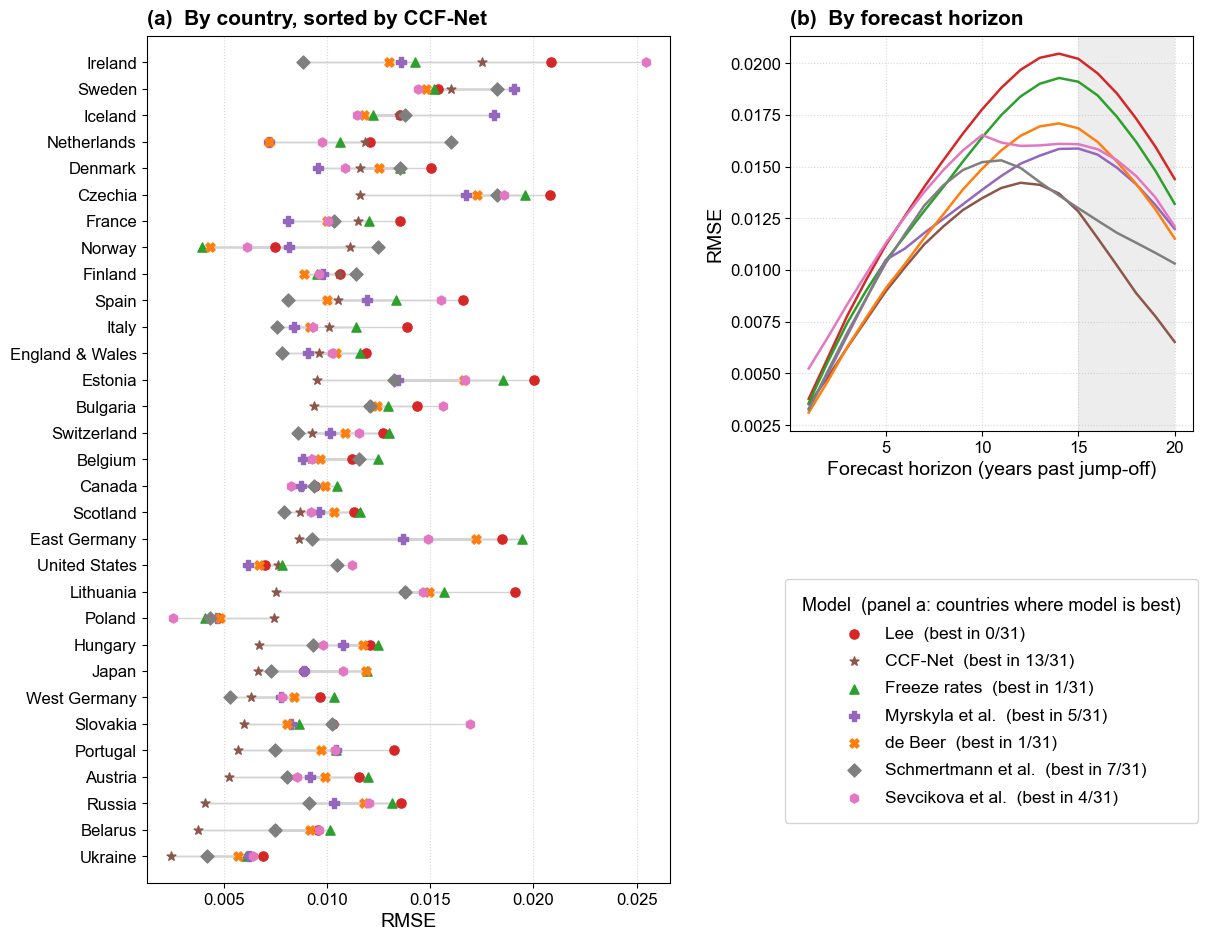

In [18]:
# ============================================================
# Figure 2: pointwise RMSE on the completed-cohort cells,
#           (a) by country and (b) by forecast horizon
# ============================================================
# Scored cells are the ones that enter the CF forecasts of the equal testing
# dataset (`common_cohorts`, as in Table 1). A cell is kept iff
#     (Country, Year, JumpOffYear) is one of those CF forecasts, and
#     Age is in the CF span (CF_AGE_LO..CF_AGE_HI)
# i.e. exactly the forecast leg (ages AAF+1..40) that gets spliced onto the
# observed history to form each forecast CF. The observed leg is not scored --
# it is identical for every method, so it carries no error. This figure and
# Table 1 therefore describe the SAME forecasts: any ranking difference is a
# difference of error metric, not of sample.
#
# Horizons run 1..20 (max = CF_AGE_HI - AAF_LO). Horizon h can only come from
# cohorts truncated at age <= CF_AGE_HI - h, so the long horizons are a small,
# old-age subset; from CF_THIN_FROM on they are shaded.
#
# Countries with fewer than CF_FIG_MIN_JOYS jump-off years are left out of the
# figure only, not out of any table.
CF_FIG_MIN_JOYS = 3                     # coverage filter: keep countries with >= this many JOYs
CF_SORT_BY = 'CCF-Net'                  # panel (a) is sorted by this model's RMSE
CF_THIN_FROM = 15                       # horizon past which the sample thins hard
CF_FIGSIZE = (13.5, 11)
CF_FS_TICK = 12                         # tick labels (incl. country names)
CF_FS_LABEL = 14                        # axis labels
CF_FS_TITLE = 15                        # panel titles
CF_FS_LEGEND = 12.5                     # legend entries

plot_labels = common_labels


def _rmse_c(d):
    return np.sqrt(np.mean((d['Rate_pred'] - d['Rate_obs']) ** 2))


def _rmse_by_h(d):
    h = d['Year'] + d['Age'] - d['JumpOffYear']
    return d.groupby(h).apply(_rmse_c)


# --- the CF forecast keys, one row per (country, birth cohort, jump-off year) ---
cf_cohort_keys = pd.DataFrame(list(common_cohorts),
                              columns=['Country', 'Year', 'JumpOffYear'])

# --- rebuild the scoring frames from scratch, then restrict to the CF cells ---
def _cf_cells(d):
    """Keep only the forecast-leg cells that feed the equal-testing-dataset CFs."""
    d = d[d['Age'].between(CF_AGE_LO, CF_AGE_HI)]   # no-op: same window as the load cell
    return d.merge(cf_cohort_keys, on=['Country', 'Year', 'JumpOffYear'], how='inner')


cf_merged_by_model = {
    l: _cf_cells(M[l]['pred'].merge(
        M[l]['obs'][obs_key + ['Rate']], on=obs_key, how='inner',
        suffixes=('_pred', '_obs')))
    for l in plot_labels
}

# every method must be scored on the identical cells for the panels to compare
_cf_sets = {l: set(map(tuple, d[key_cols].values)) for l, d in cf_merged_by_model.items()}
assert len(set(map(frozenset, _cf_sets.values()))) == 1, 'methods differ in scored cells'

# --- coverage filter ---
_cf_joys = cf_cohort_keys.groupby('Country')['JumpOffYear'].nunique()
_cf_keep = _cf_joys[_cf_joys >= CF_FIG_MIN_JOYS].index
_cf_drop = _cf_joys[_cf_joys < CF_FIG_MIN_JOYS]
cf_merged_by_model = {l: d[d['Country'].isin(_cf_keep)]
                      for l, d in cf_merged_by_model.items()}

_n_cells = len(cf_merged_by_model[CF_SORT_BY])
_n_coh = len(cf_cohort_keys[cf_cohort_keys['Country'].isin(_cf_keep)])
print(f'CF-cell scoring: {_n_cells:,} cells from {_n_coh:,} of the '
      f'{len(common_cohorts):,} CF forecasts, {len(_cf_keep)} countries '
      f'(dropped {", ".join(GEO_NAMES.get(int(c), str(c)) for c in _cf_drop.index)} '
      f'for < {CF_FIG_MIN_JOYS} jump-off years).')

# --- panel (a): RMSE by country ---
cf_rmse_country = pd.DataFrame({
    l: d.groupby('Country').apply(_rmse_c) for l, d in cf_merged_by_model.items()
})
cf_best_counts = cf_rmse_country.idxmin(axis=1).value_counts()
cf_rmse_country = cf_rmse_country.sort_values(CF_SORT_BY)
cf_country_labels = [geo_label(c) for c in cf_rmse_country.index]
y = np.arange(len(cf_rmse_country))

# --- panel (b): RMSE by forecast horizon ---
cf_rmse_horizon = pd.DataFrame({l: _rmse_by_h(d)
                                for l, d in cf_merged_by_model.items()})
cf_n_by_h = cf_merged_by_model[CF_SORT_BY].assign(
    H=lambda d: d['Year'] + d['Age'] - d['JumpOffYear']).groupby('H').size()

# ============================================================
# Layout
# ============================================================
fig = plt.figure(figsize=CF_FIGSIZE)
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.26)
ax_c = fig.add_subplot(gs[0, 0])
gs_r = gs[0, 1].subgridspec(2, 1, height_ratios=[1.2, 1], hspace=0.34)
ax_h = fig.add_subplot(gs_r[0])
ax_leg = fig.add_subplot(gs_r[1])
ax_leg.axis('off')

# --- (a) RMSE by country ---
for yi in y:                                   # connector first, behind the dots
    ax_c.plot(cf_rmse_country.iloc[yi].values, [yi] * cf_rmse_country.shape[1],
              color='lightgray', lw=1, zorder=1)
handles = []
for l in plot_labels:
    h_ = ax_c.scatter(cf_rmse_country[l], y, color=M[l]['color'],
                      marker=M[l]['marker'], s=44, zorder=3,
                      label=f'{l}  (best in {cf_best_counts.get(l, 0)}/{len(cf_rmse_country)})')
    handles.append(h_)

ax_c.set_yticks(y)
ax_c.set_yticklabels(cf_country_labels, fontsize=CF_FS_TICK)
ax_c.set_ylim(-1, len(y))
ax_c.set_xlabel('RMSE', fontsize=CF_FS_LABEL)
ax_c.tick_params(axis='x', labelsize=CF_FS_TICK)
ax_c.grid(axis='x', ls=':', alpha=0.5)
ax_c.set_axisbelow(True)
ax_c.set_title(f'(a)  By country, sorted by {CF_SORT_BY}', loc='left',
               fontsize=CF_FS_TITLE, fontweight='bold', pad=8)

# --- (b) RMSE by forecast horizon ---
ax_h.axvspan(CF_THIN_FROM, cf_rmse_horizon.index.max(), color='0.93', lw=0, zorder=0)
for l in plot_labels:
    ax_h.plot(cf_rmse_horizon.index, cf_rmse_horizon[l], color=M[l]['color'],
              lw=1.8, zorder=3)

ax_h.set_xlabel('Forecast horizon (years past jump-off)', fontsize=CF_FS_LABEL)
ax_h.set_ylabel('RMSE', fontsize=CF_FS_LABEL)
ax_h.tick_params(labelsize=CF_FS_TICK)
ax_h.grid(True, ls=':', alpha=0.5)
ax_h.set_axisbelow(True)
ax_h.set_title('(b)  By forecast horizon', loc='left',
               fontsize=CF_FS_TITLE, fontweight='bold', pad=8)

# --- shared legend ---
# pinned to the top of its slot, just under panel (b); lower the 2nd number to
# move it down (1.0 = top of the slot)
ax_leg.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.95),
              frameon=True, fontsize=CF_FS_LEGEND,
              title='Model  (panel a: countries where model is best)',
              title_fontsize=CF_FS_LEGEND + 0.5, ncol=1, borderpad=1, labelspacing=0.7)

fig.savefig('../../figures/rmse_country_and_horizon_completed_cohorts.png', dpi=300,
            bbox_inches='tight')
plt.show()

## Figure 3: CF forecast error by the cohort's age in the jump-off year

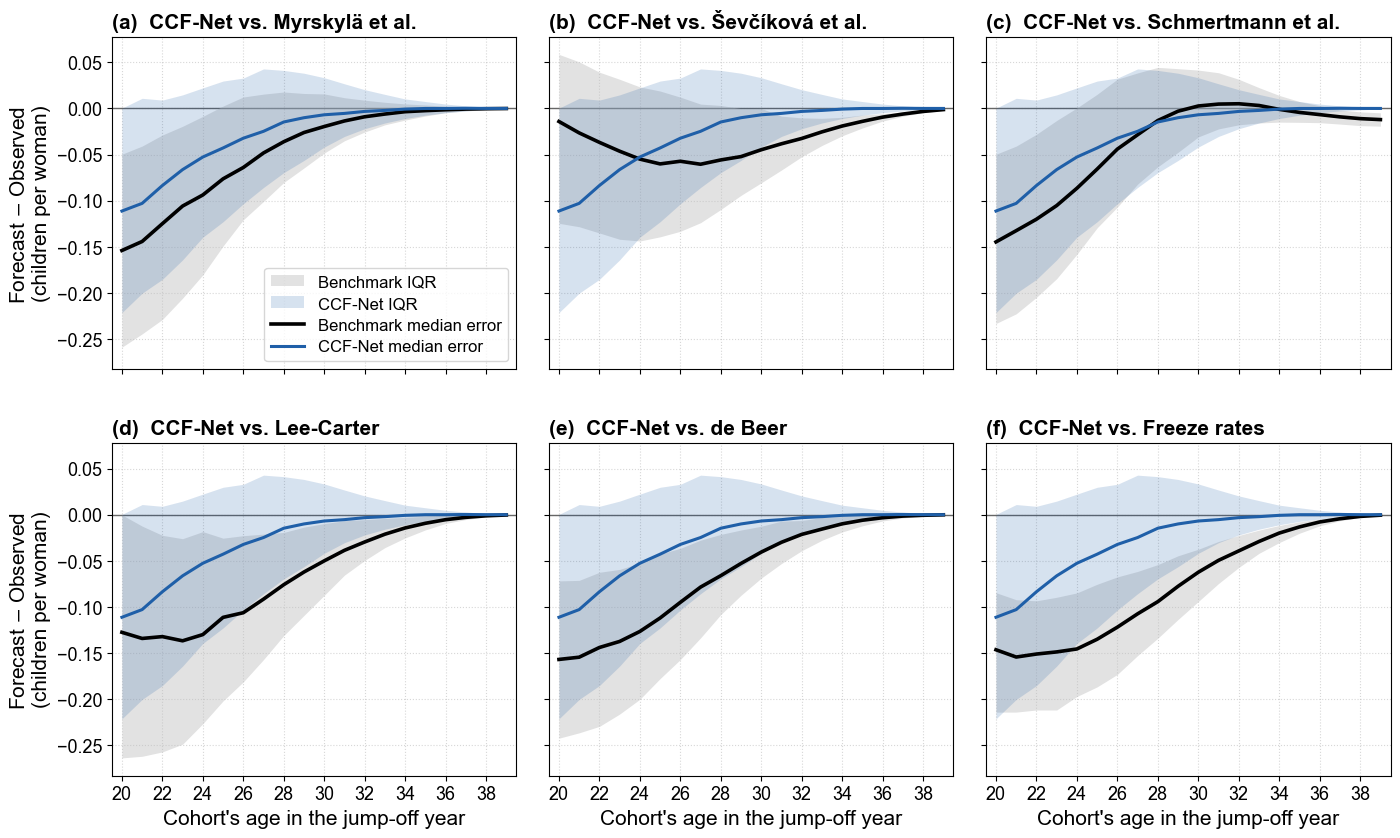

Median error (Forecast - Observed) at selected AAFs, Table 1 cells:


,cells,countries,CCF-Net @AAF 39,bench @AAF 39,CCF-Net @AAF 20,bench @AAF 20
Myrskyla et al.,11599,32,0.0,-0.000,-0.111,-0.154
Sevcikova et al.,11599,32,0.0,-0.001,-0.111,-0.014
Schmertmann et al.,11599,32,0.0,-0.012,-0.111,-0.145
Lee,11599,32,0.0,-0.000,-0.111,-0.128
de Beer,11599,32,0.0,-0.000,-0.111,-0.157
Freeze rates,11599,32,0.0,-0.001,-0.111,-0.146


In [35]:
# ============================================================
# Figure 3: CF forecast error by the cohort's age in the jump-off year (AAF),
#           CCF-Net vs. each benchmark
# ============================================================
# y = method CF40 - observed CF40 (+ = over-forecast), so 0 = a perfect forecast.
# One panel per benchmark, 2x3 on a SHARED y-axis. Every panel starts near 0 at
# AAF 39 (only age 40 is forecast) and can widen to the left.
#
#   black solid / grey band   benchmark's median error / IQR
#   blue solid  / blue band   CCF-Net's median error / IQR on the same cells
#
# SAMPLE. With FUNNEL_TABLE1_CELLS on, every panel is restricted to the Table 1
# equal testing dataset (`common_cohorts`), so all panels describe the same cells
# and CCF-Net's line and band are identical across panels; only the benchmark
# changes. Set it to False for each pair's own, larger overlap instead.
#
# SCHMERTMANN CAVEAT. True CF is from CCF-Net's RR observed frame; Schmertmann's
# spliced CF uses its native-VV observed ages, so its error at AAF 39 is not ~0
# (about +0.012) -- a data-vintage offset, not a forecasting error.
CMP_A = 'CCF-Net'
FUNNEL_BENCHMARKS = ['Myrskyla et al.', 'Sevcikova et al.', 'Schmertmann et al.',
                     'Lee', 'de Beer', 'Freeze rates']
FUNNEL_KIND = {'Myrskyla et al.': 'Myrskylä et al.',
               'Sevcikova et al.': 'Ševčíková et al.',
               'Schmertmann et al.': 'Schmertmann et al.',
               'Lee': 'Lee-Carter', 'de Beer': 'de Beer',
               'Freeze rates': 'Freeze rates'}
FUNNEL_FIGSIZE = (16.5, 9.6)
# font sizes (pt) for both funnel figures
FUNNEL_FS = dict(title=15, axlabel=15, tick=13, legend=12)
FUNNEL_TABLE1_CELLS = True                    # restrict to Table 1's graded cells
CCF_COLOR = '#1f5fa8'


def error_tables(b_label):
    """Per-AAF error summaries for CCF-Net and one benchmark, paired cells."""
    v = cf_level[CMP_A].merge(
        cf_level[b_label][['Country', 'Year', 'JumpOffYear', 'cf']],
        on=['Country', 'Year', 'JumpOffYear'], how='inner', suffixes=('_a', '_b'))
    if FUNNEL_TABLE1_CELLS:                        # Table 1's equal testing dataset
        v = v[pd.MultiIndex.from_frame(v[['Country', 'Year', 'JumpOffYear']])
              .isin(common_cohorts)]
    v = v[v['true_cf'].notna()].copy()             # cohorts complete at CF_AGE_HI
    v['err_a'] = v['cf_a'] - v['true_cf']
    v['err_b'] = v['cf_b'] - v['true_cf']
    q = lambda p: (lambda s: s.quantile(p))
    agg = dict(med='median', q25=q(.25), q75=q(.75))
    return dict(a=v.groupby('AAF')['err_a'].agg(**agg),
                b=v.groupby('AAF')['err_b'].agg(**agg),
                n=v.groupby('AAF').size(), cells=v)


_win = slice(CMP_SCORE_AAF_LO, CMP_AAF_HI)      # plotted AAF window
errors = {b: error_tables(b) for b in FUNNEL_BENCHMARKS}

fig, axes = plt.subplots(2, 3, figsize=FUNNEL_FIGSIZE, sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.08, hspace=0.22))

for ax, tag, b in zip(axes.flat, 'abcdef', FUNNEL_BENCHMARKS):
    ea, eb = errors[b]['a'], errors[b]['b']

    ax.axhline(0, color='0.4', lw=1, zorder=1)
    ax.fill_between(eb.index, eb['q25'], eb['q75'], color='0.75', alpha=0.45,
                    lw=0, zorder=2, label='Benchmark IQR')
    ax.fill_between(ea.index, ea['q25'], ea['q75'], color=CCF_COLOR, alpha=0.18,
                    lw=0, zorder=3, label='CCF-Net IQR')
    ax.plot(eb.index, eb['med'], color='black', lw=2.6, zorder=5,
            label='Benchmark median error')
    ax.plot(ea.index, ea['med'], color=CCF_COLOR, lw=2.2, zorder=6,
            label='CCF-Net median error')

    ax.set_xlim(CMP_SCORE_AAF_LO - 0.5, CMP_AAF_HI + 0.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(True, ls=':', alpha=0.5)
    ax.set_axisbelow(True)
    ax.set_title(f'({tag})  CCF-Net vs. {FUNNEL_KIND[b]}', loc='left',
                 fontsize=FUNNEL_FS['title'], fontweight='bold', pad=6)
    ax.tick_params(labelsize=FUNNEL_FS['tick'])

for ax in axes[1]:
    ax.set_xlabel("Cohort's age in the jump-off year", fontsize=FUNNEL_FS['axlabel'])
for ax in axes[:, 0]:
    ax.set_ylabel('Forecast $-$ Observed \n(children per woman)', fontsize=FUNNEL_FS['axlabel'])
axes[0, 0].legend(fontsize=FUNNEL_FS['legend'], frameon=True, loc='lower right', labelspacing=0.4)

_all = np.concatenate([e[k].loc[_win, ['q25', 'q75']].to_numpy().ravel()
                       for e in errors.values() for k in ('a', 'b')])
_pad = 0.06 * (np.nanmax(_all) - np.nanmin(_all))
axes[0, 0].set_ylim(np.nanmin(_all) - _pad, np.nanmax(_all) + _pad)

fig.savefig('../../figures/error_funnels.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'Median error (Forecast - Observed) at selected AAFs, '
      f'{"Table 1 cells" if FUNNEL_TABLE1_CELLS else "paired completed cohorts"}:')
display(pd.DataFrame.from_dict({
    b: {'cells': len(e['cells']), 'countries': e['cells']['Country'].nunique(),
        f'CCF-Net @AAF {CMP_AAF_HI}': e['a'].loc[CMP_AAF_HI, 'med'],
        f'bench @AAF {CMP_AAF_HI}': e['b'].loc[CMP_AAF_HI, 'med'],
        f'CCF-Net @AAF {CMP_SCORE_AAF_LO}': e['a'].loc[CMP_SCORE_AAF_LO, 'med'],
        f'bench @AAF {CMP_SCORE_AAF_LO}': e['b'].loc[CMP_SCORE_AAF_LO, 'med']}
    for b, e in errors.items()}, orient='index').round(3))

## Figure 4: completed cohort fertility by country, jump-off year 2005

Defines `plot_cf_by_country`, which Figure A2 (end of notebook) reuses for 2010.

In [ ]:
# ============================================================
# Figures 4 and A2: completed cohort fertility by country, observed vs.
#                  CCF-Net and Myrskyla et al., one jump-off year
# ============================================================
# One panel per country, x = birth cohort, y = completed cohort fertility (CF,
# ages CF_AGE_LO..CF_AGE_HI). Three lines per panel:
#   black   observed CF -- every cohort the data actually completes, drawn well
#           before the forecast window so each country's level and trend are
#           visible;
#   CCF-Net and Myrskyla et al.  the CF each method implies for the cohorts still
#           open at the jump-off year, i.e. observed ages 15..AAF spliced onto
#           forecast ages AAF+1..CF_AGE_HI (`cf_level`).
#
# The forecast lines run right-to-left in horizon: the leftmost forecast cohort
# was aged PANEL_AAF_HI at the jump-off (one age forecast, so it sits on top of
# the observed line), the rightmost was aged PANEL_AAF_LO (twenty ages forecast).
# Where the black line has ended, the cohort is not yet complete in that
# country's data and there is no truth to compare the forecasts against -- that
# region is shaded, per country.
#
# Figure 4 is jump-off year 2005; Figure A2 is 2010.
PANEL_METHODS = ['CCF-Net', 'Myrskyla et al.']
PANEL_AAF_LO, PANEL_AAF_HI = CMP_SCORE_AAF_LO, CMP_AAF_HI   # scored window, 20-39
PANEL_LEAD_IN = 12                                  # observed cohorts shown before

# --- geometry, set for the page this is printed on ---------------------------
# LaTeX scales the whole PNG, fonts included: \includegraphics[width=\textwidth]
# on a 15-inch-wide figure shrinks every label to 0.43x, which is why the text
# reads small in the document however large the fontsize argument was. So the
# figure is BUILT at roughly its printed size and the fonts are set in real
# points. Keep FIG_WIDTH_IN at (or just above) your \textwidth and the type
# comes out the size it says here.
PANEL_NCOLS = 4         # narrow and tall
PANEL_PAGES = 2         # split the countries over this many PNGs, one per page.
                        # A single image cannot break across pages in LaTeX, so
                        # spreading out lengthwise means emitting two files and
                        # floating them on consecutive pages (see the printout).
FIG_WIDTH_IN = 7.0      # ~\textwidth. 6.5 for stock article, ~7.0 for wider styles
PANEL_ASPECT = 0.95     # panel height / width. With 35 countries over 2 pages
                        # each page is 5 rows, so the panels can be near-square
                        # and still fill only one page; at PANEL_PAGES = 1 this
                        # has to drop to ~0.55 for the figure to fit at all.
EXTRA_H_IN = 0.6        # room for the suptitle and the shared x label
FS_TICK, FS_TITLE, FS_AXLAB, FS_LEG, FS_SUP = 8.5, 9.5, 11, 10, 11.5
TEXTWIDTH_IN = 6.5      # your \textwidth, for the scale report printed below
# Countries kept out of the grid. GBR_NP and DEUTNP are whole-country aggregates
# whose constituent populations already have panels of their own (England &
# Wales / Scotland / N. Ireland, and East / West Germany), so they add no
# independent case; KOR completes no cohort inside the plotted window, which
# leaves a panel of forecast points with no observed line to read them against.
# Only this figure is affected -- every table above still scores all countries.
PANEL_EXCLUDE = {'KOR', 'GBR_NP', 'DEUTNP', 'HRV'}

# observed CF for every cohort the data completes (ages CF_AGE_LO..CF_AGE_HI).
# Taken from CCF-Net's observed frame; it is bit-identical to Myrskyla's, so the black
# line is the same truth for both forecasts.
_obs = (pd.read_csv(f"{DATA_DIR}/{MODEL_REGISTRY['CCF-Net']['obs']}.csv")
        .query('@CF_AGE_LO <= Age <= @CF_AGE_HI')[['Country', 'Year', 'Age', 'Rate']]
        .drop_duplicates(['Country', 'Year', 'Age']))
_n_ages = _obs.groupby(['Country', 'Year'])['Age'].transform('nunique')
obs_cf_all = (_obs[_n_ages == N_CF_AGES].groupby(['Country', 'Year'])['Rate']
              .sum().rename('cf').reset_index())


def plot_cf_by_country(panel_joy):
    """Draw and save the CF-by-country grid for one jump-off year."""
    # forecast CF at this jump-off year, per method
    panel_fc = {
        label: cf_level[label].query(
            'JumpOffYear == @panel_joy and @PANEL_AAF_LO <= AAF <= @PANEL_AAF_HI')
        for label in PANEL_METHODS
    }

    # countries both methods forecast at this jump-off year, minus the exclusions
    _shared = set.intersection(*(set(df['Country']) for df in panel_fc.values()))
    panel_geos = sorted((c for c in _shared
                         if GEO_NAMES.get(int(c), str(c)) not in PANEL_EXCLUDE),
                        key=geo_label)
    _dropped = sorted(set().union(*(set(df['Country']) for df in panel_fc.values())) - _shared)

    cohort_lo = panel_joy - PANEL_AAF_HI                # oldest forecast cohort
    cohort_hi = panel_joy - PANEL_AAF_LO                # youngest forecast cohort
    obs_cf = obs_cf_all[obs_cf_all['Year'].between(cohort_lo - PANEL_LEAD_IN, cohort_hi)]
    _last_by_geo = obs_cf.groupby('Country')['Year'].max()   # truth ends here, per country

    print(f'CF by country at jump-off {panel_joy}: {len(panel_geos)} countries, '
          f'cohorts {cohort_lo}-{cohort_hi} forecast (AAF {PANEL_AAF_HI} down to '
          f'{PANEL_AAF_LO}), observed back to {cohort_lo - PANEL_LEAD_IN}.')
    print(f'  last cohort complete in the data: {int(_last_by_geo.min())}-'
          f'{int(_last_by_geo.max())} depending on the country (shaded from there on, '
          f'where the forecasts cannot yet be checked).')
    _no_truth = [g for g in panel_geos if not (obs_cf['Country'] == g).any()]
    if _no_truth:
        print('  no completed cohort in the plotted window (forecast lines only): '
              + ', '.join(GEO_NAMES.get(int(c), str(c)) for c in _no_truth))
    if PANEL_EXCLUDE:
        print('  excluded by hand: ' + ', '.join(sorted(PANEL_EXCLUDE)))
    if _dropped:
        print('  dropped (not forecast by both methods): '
              + ', '.join(GEO_NAMES.get(int(c), str(c)) for c in _dropped))

    # Shared y limits across BOTH pages -- sharey only couples panels within one
    # figure, and a country's level must mean the same thing on page 1 and page 2.
    _plotted = np.concatenate(
        [obs_cf[obs_cf['Country'].isin(panel_geos)]['cf'].values]
        + [df[df['Country'].isin(panel_geos)]['cf'].values for df in panel_fc.values()])
    PANEL_YLIM = (np.floor(_plotted.min() * 10) / 10 - 0.05,
                  np.ceil(_plotted.max() * 10) / 10 + 0.05)

    _pages = [list(p) for p in np.array_split(np.array(panel_geos, dtype=object),
                                              PANEL_PAGES)]
    _written = []

    for _pg, _geos in enumerate(_pages, start=1):
        nrows = -(-len(_geos) // PANEL_NCOLS)
        _panel_w = FIG_WIDTH_IN / PANEL_NCOLS
        fig, axes = plt.subplots(
            nrows, PANEL_NCOLS, sharex=True, sharey=True, layout='constrained',
            figsize=(FIG_WIDTH_IN, nrows * _panel_w * PANEL_ASPECT + EXTRA_H_IN))
        axes = np.atleast_1d(axes).ravel()

        for ax, geo in zip(axes, _geos):
            o = obs_cf[obs_cf['Country'] == geo].sort_values('Year')

            # shaded: cohorts this country does not complete in the data, so the
            # forecasts there cannot be checked against anything (the cut-off
            # differs per country -- the observed series do not all end in the same
            # year; it is the country's last data year minus CF_AGE_HI)
            _last = o['Year'].max() if len(o) else cohort_lo - PANEL_LEAD_IN
            ax.axvspan(_last, cohort_hi + 0.6, color='0.88', lw=0, zorder=0)

            ax.plot(o['Year'], o['cf'], color='black', lw=1.6, zorder=5, label='Observed')

            for label in PANEL_METHODS:
                f = panel_fc[label][panel_fc[label]['Country'] == geo].sort_values('Year')
                ax.plot(f['Year'], f['cf'], color=M[label]['color'], lw=1.4, zorder=4,
                        label=label)

            ax.set_title(geo_label(geo), fontsize=FS_TITLE,
                         fontweight='bold', pad=2.5)
            ax.grid(True, ls=':', alpha=0.5)
            ax.set_axisbelow(True)
            ax.tick_params(labelsize=FS_TICK, length=2.5, pad=1.5)

        # sparse ticks: the panels are narrow, and every one of them carries the label
        axes[0].set_xlim(cohort_lo - PANEL_LEAD_IN, cohort_hi + 0.6)
        axes[0].set_xticks([1960, 1970, 1980])
        axes[0].set_ylim(*PANEL_YLIM)
        axes[0].set_yticks([1.0, 1.5, 2.0, 2.5])

        for ax in axes[len(_geos):]:
            ax.axis('off')
        # the last row is ragged, so restore x tick labels on the lowest live panel
        # of every column (sharex hides them everywhere but the bottom grid row)
        for col in range(PANEL_NCOLS):
            live = [k for k in range(col, len(_geos), PANEL_NCOLS)]
            if live:
                axes[live[-1]].tick_params(labelbottom=True)

        # legend rides in the first unused grid slot, on EVERY page -- each page is
        # torn out and read on its own. If a page happens to be full it goes under
        # the panels instead.
        handles, labels = axes[0].get_legend_handles_labels()
        _spare = axes[len(_geos)] if len(_geos) < len(axes) else None
        if _spare is not None:
            _spare.legend(handles, labels, loc='center', frameon=False, fontsize=FS_LEG,
                          handlelength=1.9, labelspacing=0.7, borderpad=0.2)
        else:
            fig.legend(handles, labels, loc='outside lower center', ncol=3,
                       frameon=False, fontsize=FS_LEG)

        fig.supxlabel('Birth cohort', fontsize=FS_AXLAB)
        fig.supylabel(f'Completed cohort fertility, ages {CF_AGE_LO}-{CF_AGE_HI} '
                      '(children per woman)', fontsize=FS_AXLAB)
        # kept short so it does not force the figure wider than FIG_WIDTH_IN (a long
        # suptitle silently widens the saved PNG under bbox_inches='tight'). Set to
        # None if the LaTeX \caption already says this.
        _part = f' ({_pg} of {PANEL_PAGES})' if PANEL_PAGES > 1 else ''
        fig.suptitle(f'Completed cohort fertility by country, jump-off year '
                     f'{panel_joy}{_part}', fontsize=FS_SUP, fontweight='bold')

        _suffix = f'_p{_pg}of{PANEL_PAGES}' if PANEL_PAGES > 1 else ''
        _png = f'../../figures/cf_by_country_joy{panel_joy}{_suffix}.png'
        fig.savefig(_png, dpi=300, bbox_inches='tight')
        _written.append((_png, *fig.get_size_inches(), len(_geos)))
        plt.show()

    # What the type will actually measure on the page: LaTeX scales the PNG by
    # textwidth / figure width, and every font size scales with it.
    _scale = TEXTWIDTH_IN / _written[0][1]
    print()
    for _png, _w, _h, _n in _written:
        print(f'Saved {_png}  ({_w:.2f} x {_h:.2f} in, {_n} countries, '
              f'prints {_w * _scale:.2f} x {_h * _scale:.2f} in)')
    print(f'  at width=\\textwidth ({TEXTWIDTH_IN} in): scale {_scale:.2f}, tick labels '
          f'{FS_TICK * _scale:.1f} pt, panel titles {FS_TITLE * _scale:.1f} pt.')
    if PANEL_PAGES > 1:
        print('  LaTeX (\\ContinuedFloat needs the caption/subcaption package):')
        print('    \\begin{figure}[p]\\centering\\includegraphics[width=\\textwidth]{'
              + _written[0][0].split('/')[-1] + '}')
        print('    \\caption{...}\\label{fig:cf_by_country}\\end{figure}')
        print('    \\begin{figure}[p]\\ContinuedFloat\\centering'
              '\\includegraphics[width=\\textwidth]{'
              + _written[1][0].split('/')[-1] + '}')
        print('    \\caption{(continued)}\\end{figure}')


plot_cf_by_country(2005)   # Figure 4

## Figure 5: pointwise RMSE by jump-off year on completed-cohort cells

Pointwise RMSE on the CF forecast cells: 108,560 cells (ages 15-40) from the 11,599 CF forecasts of the equal testing dataset, identical cells for all 7 methods.
Cells dropped per method by the equalizing step: Lee 0, CCF-Net 0, Freeze rates 0, Myrskyla et al. 0, de Beer 0, Schmertmann et al. 0, Sevcikova et al. 0


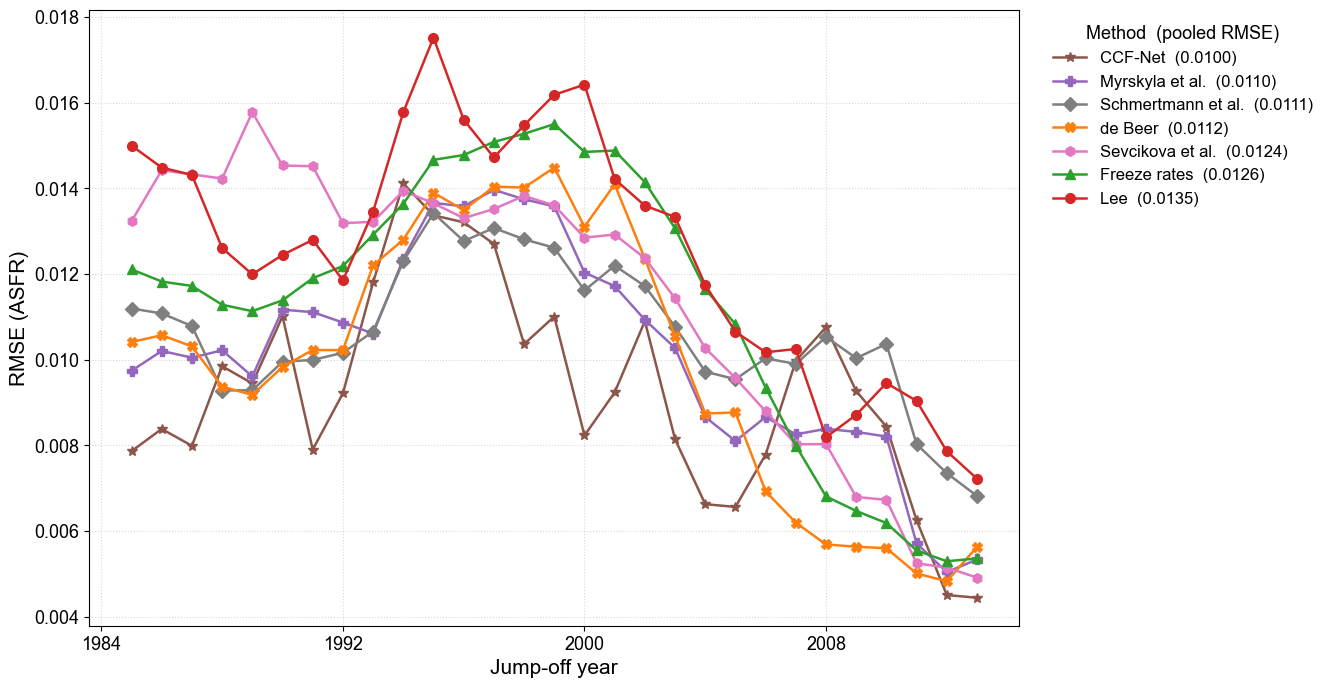

In [9]:
# ============================================================
# Figure 5: pointwise RMSE by jump-off year, on the completed-cohort cells
# ============================================================
# Table 1 collapses each forecast to one number per cohort (the APE of
# the cohort total). This cell keeps the SAME forecasts but scores them cell by
# cell: RMSE of predicted vs observed ASFR, split by jump-off year. Any ranking
# difference between the two is therefore a difference of METRIC, not of sample.
#
# Scored cells: exactly the forecast leg of the equal testing dataset, i.e. a cell
# is kept iff (Country, cohort, JumpOffYear) is one of the CF forecasts in
# `common_cohorts` and Age is inside the CF span. The observed leg (ages 15..AAF)
# is identical for every method and carries no error, so it is not scored. The
# cell set is then intersected across methods, so every column below describes the
# identical cells. With the current registry (every model on the common grid) that
# step drops nothing -- the printed drop counts are all zero -- but it keeps the
# table honest if a method that forecasts a restricted grid is added later.
#
# Later jump-off years are not "easier" versions of the earlier ones: each JOY
# brings its own cohort set (AAF 20-39 at that JOY), so the columns are separate
# samples, not a nested sequence.
from matplotlib.ticker import MaxNLocator

JOY_FIGSIZE = (12, 8)
JOY_LABEL_FS = 15      # axis labels
JOY_TICK_FS = 13       # tick numbers
JOY_LEGEND_FS = 12     # legend entries
JOY_LEGEND_TITLE_FS = 13

# one row per CF forecast: (country, birth cohort, jump-off year)
cf_keys = pd.DataFrame(list(common_cohorts), columns=['Country', 'Year', 'JumpOffYear'])


def _cf_forecast_cells(label):
    """Predicted vs observed ASFR for the cells feeding this method's CF forecasts."""
    m = M[label]
    d = m['pred'].merge(m['obs'][obs_key + ['Rate']], on=obs_key, how='inner',
                        suffixes=('_pred', '_obs'))
    d = d[d['Age'].between(CF_AGE_LO, CF_AGE_HI)]
    return d.merge(cf_keys, on=['Country', 'Year', 'JumpOffYear'], how='inner')


cf_cells_by_model = {l: _cf_forecast_cells(l) for l in models}
_n_before = {l: len(d) for l, d in cf_cells_by_model.items()}

# equalize: keep only cells every method scores, so the columns are comparable
_shared_cells = None
for d in cf_cells_by_model.values():
    k = d[key_cols].drop_duplicates()
    _shared_cells = k if _shared_cells is None else _shared_cells.merge(k, on=key_cols, how='inner')
cf_cells_by_model = {l: d.merge(_shared_cells, on=key_cols, how='inner')
                     for l, d in cf_cells_by_model.items()}


def _rmse_cells(d):
    return np.sqrt(np.mean((d['Rate_pred'] - d['Rate_obs']) ** 2))


rmse_joy_cf = pd.DataFrame({l: d.groupby('JumpOffYear').apply(_rmse_cells)
                            for l, d in cf_cells_by_model.items()})
rmse_joy_cf.loc['All JOYs'] = {l: _rmse_cells(d) for l, d in cf_cells_by_model.items()}
rmse_joy_cf = rmse_joy_cf[rmse_joy_cf.loc['All JOYs'].sort_values().index]   # best first
rmse_joy_cf.insert(0, 'N cells', pd.concat([
    cf_cells_by_model[rmse_joy_cf.columns[1]].groupby('JumpOffYear').size(),
    pd.Series({'All JOYs': len(_shared_cells)})]))

print(f'Pointwise RMSE on the CF forecast cells: {len(_shared_cells):,} cells '
      f'(ages {CF_AGE_LO}-{CF_AGE_HI}) from the {len(common_cohorts):,} CF forecasts of the '
      f'equal testing dataset, identical cells for all {len(models)} methods.')
print('Cells dropped per method by the equalizing step: '
      + ', '.join(f'{l} {n - len(_shared_cells):,}' for l, n in _n_before.items()))

# ============================================================
# Figure: one line per method
# ============================================================
_joys = rmse_joy_cf.index[:-1]                      # drop the pooled row
fig, ax = plt.subplots(figsize=JOY_FIGSIZE)
for l in rmse_joy_cf.columns[1:]:                   # already sorted best -> worst
    ax.plot(_joys, rmse_joy_cf.loc[_joys, l], color=M[l]['color'], marker=M[l]['marker'],
            markersize=7, lw=1.8, label=f"{l}  ({rmse_joy_cf.loc['All JOYs', l]:.4f})")

ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))   # a few years, not every JOY
ax.set_xlabel('Jump-off year', fontsize=JOY_LABEL_FS)
ax.set_ylabel('RMSE (ASFR)', fontsize=JOY_LABEL_FS)
ax.tick_params(axis='both', labelsize=JOY_TICK_FS)
ax.grid(True, ls=':', alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title='Method  (pooled RMSE)', fontsize=JOY_LEGEND_FS,
          title_fontsize=JOY_LEGEND_TITLE_FS,
          loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)

fig.savefig('../../figures/rmse_by_jumpoff_completed_cohorts.png', dpi=300,
            bbox_inches='tight')
plt.show()

## Table A3: CCF-Net ensemble members scored individually

In [37]:
# ============================================================
# Table A3: CCF-Net ensemble members scored individually
# ============================================================
# The reported CCF-Net series is the per-cell MEAN over several independent
# training runs ("seeds") that are identical in data, window and
# hyperparameters and differ only in weight initialization and batch sampling.
# This cell scores every member on its own, so the headline number can be read
# against the spread of the runs that produced it. Both headline metrics are
# recomputed per member -- pointwise RMSE on the common grid (`rmse`
# below) and completed-fertility APE on the equal testing dataset (as in
# `accuracy_table`) -- so the member rows are like-for-like with the two
# benchmark rows printed underneath.
#
# WHY THE ENSEMBLE BEATS EVERY INDIVIDUAL MEMBER. This is guaranteed, not a
# coincidence and not a bug. For squared error the ambiguity decomposition
# (Krogh & Vedelsby 1995) holds exactly:
#
#     MSE(mean of members) = mean member MSE - mean across-member disagreement
#
# where disagreement is the per-cell variance of the members' predictions. The
# subtracted term is a variance, so the ensemble is never worse than the average
# member, and it beats the BEST member whenever the members' errors are only
# partly correlated. The identity is verified numerically below; the residual
# should be at floating-point noise.
#
# The last block extrapolates MSE(M) = MSE_inf + sigma^2 / M, which puts the
# reported figure on a curve rather than treating the ensemble size as
# incidental. Note the measured disagreement is taken about the M-member mean,
# so it understates the single-run variance by (M-1)/M; sigma^2 corrects for it.
ENSEMBLE_LABEL = 'CCF-Net'
SEED_IDS = [0, 1, 2, 3, 4]
BENCH_REF = ['Schmertmann et al.', 'Myrskyla et al.']   # rows for context
DECIMALS_ENS = 5


def rmse(pred_df, obs_df):
    """Pointwise RMSE of predicted vs observed rates, and the number of cells."""
    merged = pred_df.merge(obs_df[obs_key + ['Rate']], on=obs_key, how='inner',
                           suffixes=('_pred', '_obs'))
    return np.sqrt(np.mean((merged['Rate_pred'] - merged['Rate_obs']) ** 2)), len(merged)


_ens_base = MODEL_REGISTRY[ENSEMBLE_LABEL]['pred']
_ens_obs = M[ENSEMBLE_LABEL]['obs']
_ens_grid = M[ENSEMBLE_LABEL]['pred'][key_cols]   # post-jump-off, common grid


def _load_member(seed):
    """One ensemble member, filtered and narrowed exactly like the registry series."""
    df = pd.read_csv(f'{DATA_DIR}/{_ens_base}_seed{seed}.csv')
    df = df[df['Year'] + df['Age'] > df['JumpOffYear']]
    return df.merge(_ens_grid, on=key_cols, how='inner')


members = {}
for _s in SEED_IDS:
    try:
        members[_s] = _load_member(_s)
    except FileNotFoundError:
        print(f'  no file for seed {_s} ({_ens_base}_seed{_s}.csv) -- skipped')
if not members:
    raise FileNotFoundError(f'no ensemble members found for {_ens_base}')


def _row(name, pred_df, obs_df, ape):
    err, n = rmse(pred_df, obs_df)
    return {'Series': name, 'RMSE': err, 'CF median APE': ape.median(),
            'CF mean APE': ape.mean(), 'CF P95 APE': ape.quantile(0.95), 'N cells': n}


_rows_ens = []
for _s, _df in members.items():
    _a = cf_ape(_ens_obs, _df).reindex(common_cohorts)
    if _a.isna().any():
        print(f'  warning: seed {_s} is missing {int(_a.isna().sum())} of the '
              f'{len(common_cohorts):,} common CF forecasts')
    _rows_ens.append(_row(f'seed {_s}', _df, _ens_obs, _a))

_rows_ens.append(_row(f'ENSEMBLE (mean of {len(members)})',
                      M[ENSEMBLE_LABEL]['pred'], _ens_obs, ape_by_model[ENSEMBLE_LABEL]))
for _b in BENCH_REF:
    _rows_ens.append(_row(f'[benchmark] {_b}', M[_b]['pred'], M[_b]['obs'], ape_by_model[_b]))

ensemble_table = pd.DataFrame(_rows_ens).set_index('Series')

# --- ambiguity decomposition, on exactly the scored cells -------------------
_w = (_ens_grid.merge(_ens_obs[obs_key + ['Rate']], on=obs_key, how='inner')
      .rename(columns={'Rate': 'y'}))
for _s, _df in members.items():
    _w = _w.merge(_df[key_cols + ['Rate']].rename(columns={'Rate': f'm{_s}'}),
                  on=key_cols, how='inner')
_mcols = [f'm{_s}' for _s in members]
_M_ENS = len(_mcols)
_fbar = _w[_mcols].mean(axis=1)
_mse_members = np.array([((_w[c] - _w['y']) ** 2).mean() for c in _mcols])
_mse_bar = _mse_members.mean()
_mse_ens = ((_fbar - _w['y']) ** 2).mean()
_amb = (_w[_mcols].sub(_fbar, axis=0) ** 2).mean(axis=1).mean()
_err_corr = pd.DataFrame({c: _w[c] - _w['y'] for c in _mcols}).corr().values
_off = _err_corr[np.triu_indices(_M_ENS, 1)]

print(f'Ensemble members: {_M_ENS} seeds of {_ens_base}, scored on '
      f'{len(_w):,} cells of the common grid.\n')
print(ensemble_table.round(DECIMALS_ENS).to_string())

print(f'\nAmbiguity decomposition (pointwise MSE, {len(_w):,} cells)')
print(f'  mean member MSE            {_mse_bar:.6e}   (RMSE {np.sqrt(_mse_bar):.5f})')
print(f'- mean member disagreement   {_amb:.6e}   (RMS spread {np.sqrt(_amb):.5f})')
print(f'= ensemble MSE               {_mse_ens:.6e}   (RMSE {np.sqrt(_mse_ens):.5f})')
print(f'  identity residual          {abs(_mse_bar - _amb - _mse_ens):.2e}')
print(f'\n  seed noise is {100 * _amb / _mse_bar:.1f}% of the average single-run MSE')
print(f'  pairwise correlation of member errors: mean {_off.mean():.3f} '
      f'(range {_off.min():.3f}-{_off.max():.3f}); 1.0 would mean ensembling cannot help')

_sigma2 = _amb * _M_ENS / (_M_ENS - 1)      # about the infinite-ensemble mean
_mse_inf = _mse_bar - _sigma2
print(f'\nImplied RMSE by ensemble size,  MSE(M) = {_mse_inf:.4e} + {_sigma2:.4e} / M')
for _m in [1, 2, 3, 5, 10, 25]:
    _mark = '   <- reported' if _m == _M_ENS else ''
    print(f'  M = {_m:>2}   RMSE {np.sqrt(_mse_inf + _sigma2 / _m):.5f}{_mark}')
print(f'  M -> inf  RMSE {np.sqrt(_mse_inf):.5f}')
print('  benchmarks: ' + ', '.join(
    f'{b} {rmse(M[b]["pred"], M[b]["obs"])[0]:.5f}' for b in BENCH_REF))

# --- LaTeX ------------------------------------------------------------------
_tex_rows = []
for _name, _r in ensemble_table.iterrows():
    _lab = _name.replace('[benchmark] ', r'\quad ').replace('_', r'\_')
    if _name.startswith('ENSEMBLE'):
        _lab = r'\textbf{' + _lab + '}'
    _tex_rows.append(f"{_lab} & {_r['RMSE']:.5f} & {_r['CF median APE']:.2f} & "
                     f"{_r['CF mean APE']:.2f} & {_r['CF P95 APE']:.2f} \\\\")
print('\n' + '\n'.join([
    r'\begin{table}[htbp]', r'\centering',
    r'\caption{CCF-Net ensemble members scored individually. Pointwise RMSE is on '
    f'the {len(_w):,} common-grid cells; CF columns are absolute percentage errors of '
    f'completed cohort fertility on the equal testing dataset of {len(common_cohorts):,} '
    r'forecasts. The ensemble is the per-cell mean of the members above it; two '
    r'benchmarks are shown for context.}',
    r'\label{tab:ensemble_members}', r'\begin{tabular}{lrrrr}', r'\toprule',
    r'Series & RMSE & \multicolumn{3}{c}{CF APE, \%} \\',
    r'\cmidrule(lr){3-5}', r' & & median & mean & P95 \\', r'\midrule',
    '\n'.join(_tex_rows[:len(members)]), r'\midrule',
    '\n'.join(_tex_rows[len(members):len(members) + 1]), r'\midrule',
    '\n'.join(_tex_rows[len(members) + 1:]),
    r'\bottomrule', r'\end{tabular}', r'\end{table}']))

Ensemble members: 5 seeds of dl_forecasts_u110_l4_d0.0_w40_freeze_alljoys, scored on 197,361 cells of the common grid.

                                   RMSE  CF median APE  CF mean APE  CF P95 APE  N cells
Series                                                                                  
seed 0                          0.01391        1.47129      3.38772    13.22804   197361
seed 1                          0.01472        1.39446      3.64985    14.91363   197361
seed 2                          0.01296        1.32171      3.27239    13.03894   197361
seed 3                          0.01530        1.46971      3.82433    15.65934   197361
seed 4                          0.01461        1.25413      3.51708    14.90622   197361
ENSEMBLE (mean of 5)            0.01242        1.15063      3.02148    12.19109   197361
[benchmark] Schmertmann et al.  0.01401        1.28660      3.09022    11.65966   197361
[benchmark] Myrskyla et al.     0.01421        1.07273      3.13570    13.30919

## Figure A2: completed cohort fertility by country, jump-off year 2010

CF by country at jump-off 2010: 35 countries, cohorts 1971-1990 forecast (AAF 39 down to 20), observed back to 1959.
  last cohort complete in the data: 1973-1984 depending on the country (shaded from there on, where the forecasts cannot yet be checked).
  excluded by hand: DEUTNP, GBR_NP, HRV, KOR


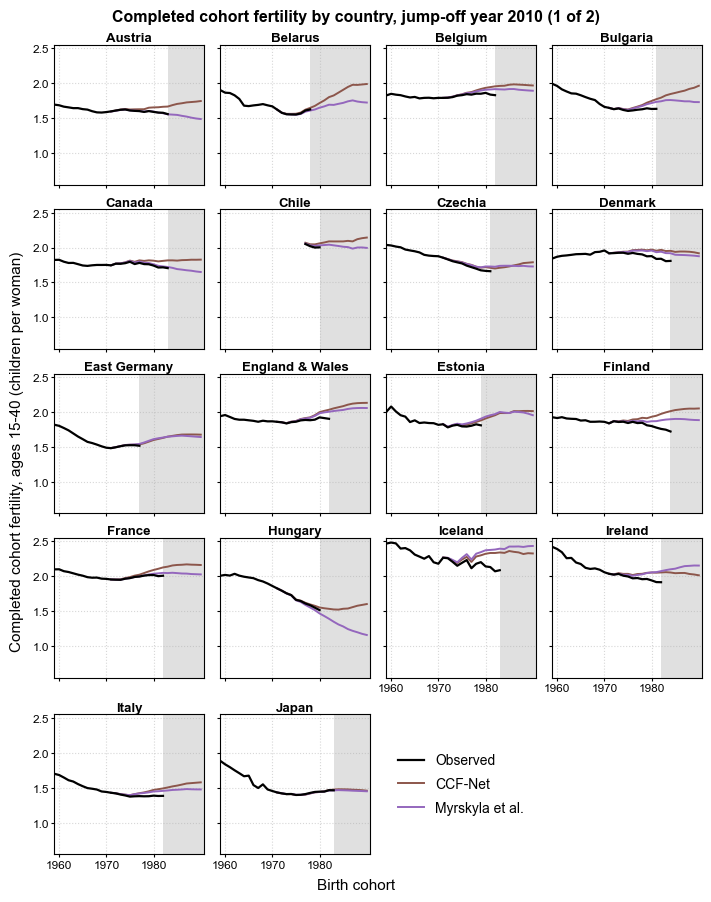

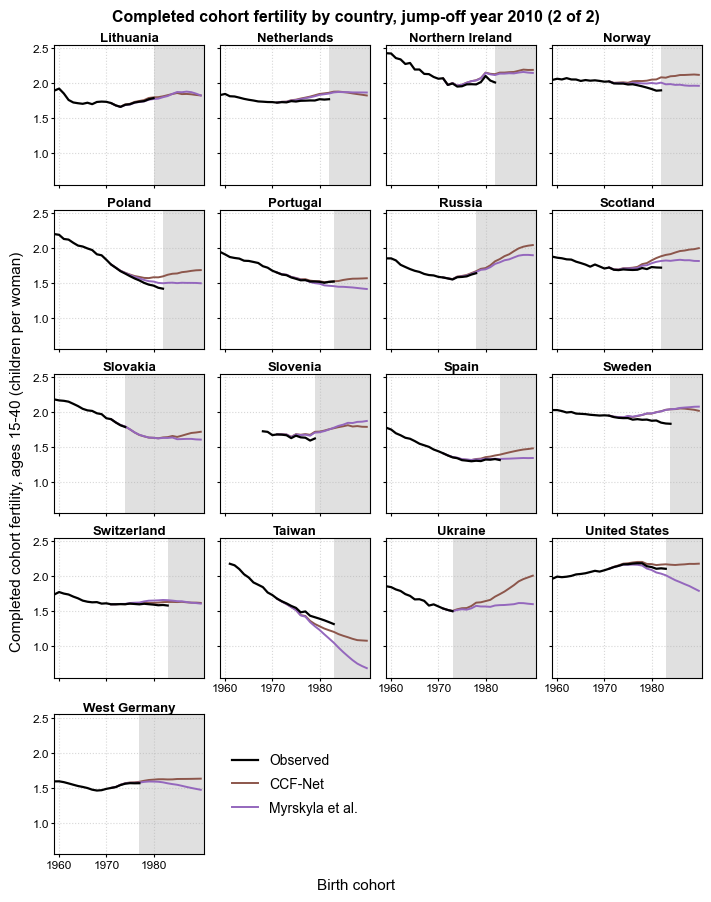


Saved ../../figures/cf_by_country_joy2010_p1of2.png  (7.00 x 8.91 in, 18 countries, prints 6.50 x 8.28 in)
Saved ../../figures/cf_by_country_joy2010_p2of2.png  (7.00 x 8.91 in, 17 countries, prints 6.50 x 8.28 in)
  at width=\textwidth (6.5 in): scale 0.93, tick labels 7.9 pt, panel titles 8.8 pt.
  LaTeX (\ContinuedFloat needs the caption/subcaption package):
    \begin{figure}[p]\centering\includegraphics[width=\textwidth]{cf_by_country_joy2010_p1of2.png}
    \caption{...}\label{fig:cf_by_country}\end{figure}
    \begin{figure}[p]\ContinuedFloat\centering\includegraphics[width=\textwidth]{cf_by_country_joy2010_p2of2.png}
    \caption{(continued)}\end{figure}


In [36]:
plot_cf_by_country(2010)   # Figure A2